C:\Users\LJC\AppData\Local\Temp\ipykernel_283440\2551105869.py:3: DtypeWarning: Columns (0: CALL_SIGN, 1: AA3, 2: AG1, 3: AJ1, 4: AW1, 5: AZ1, 6: CALL_SIGN.1, 7: GA5, 8: GE1, 9: HL1, 10: IA2, 11: KA2, 12: ME1, 13: MW3, 14: OA1, 15: OD1, 16: OD2, 17: SA1, 18: UA1, 19: UG1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('Baoan_Weather_1998_2022.csv')


有效TMP条数: 234877 / 235674
质量代码分布: {'1': 234863, '2': 13, '5': 1}
最终有效记录数: 234863
月数: 298
Linear trend slope: 0.003235 °C/month
Approx. trend per decade: 0.388 °C/decade
Total change over period: 0.961 °C


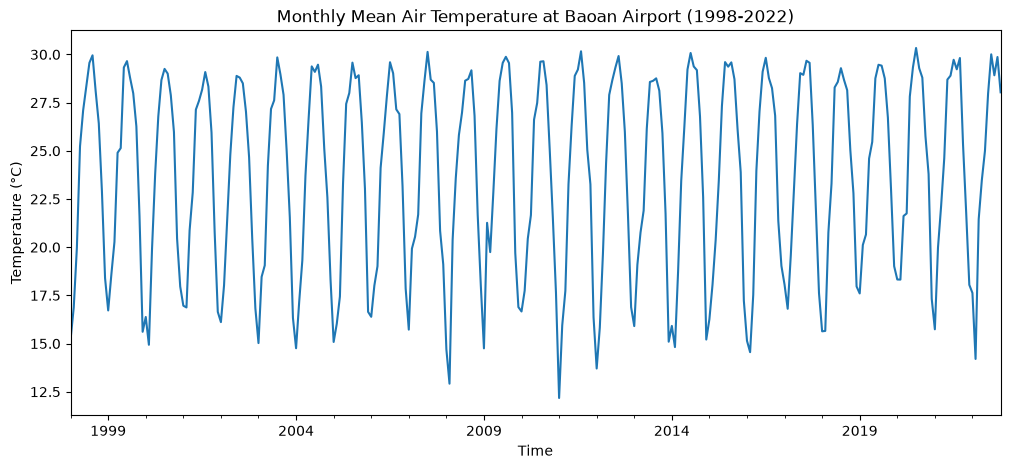

In [3]:
import pandas as pd
import numpy as np
df = pd.read_csv('Baoan_Weather_1998_2022.csv')

# TMP 
# TMP 格式: "+0186,1"  => 数值 +0186 (0.1°C, 即 18.6°C), 质量代码 1
tmp = df['TMP'].astype(str).str.strip()

# 按逗号拆成数值、质量代码两部分
parts = tmp.str.split(',', n=1, expand=True)

# 有效条件: 有两部分, 第一部分是 符号+4位数字, 第二部分是单个数字
valid = (
    parts[0].str.match(r'^[+-]\d{4}$', na=False) &
    parts[1].str.match(r'^\d$', na=False) &
    (parts[0].str[1:5] != '9999')          # 9999 = 缺失值
)
print('有效TMP条数:', valid.sum(), '/', len(tmp))

val_str = parts[0][valid]
sign = val_str.str[0]
value = val_str.str[1:5].astype(float) / 10.0

#按符号生成温度 Series
temp_c = pd.Series(np.where(sign == '-', -value, value), index=val_str.index)

quality = parts[1][valid]
print('质量代码分布:', quality.value_counts().to_dict())

#只保留质量代码 1 (通过全部质检)
mask_qc = quality == '1'
df_valid = df.loc[mask_qc[mask_qc].index].copy()
df_valid['TEMP_C'] = temp_c[mask_qc]

#解析 DATE
# DATE 形如 "1998-01-01T00:00:00"
df_valid['DATE_DT'] = pd.to_datetime(df_valid['DATE'], errors='coerce')
df_valid = df_valid.dropna(subset=['DATE_DT', 'TEMP_C'])
print('最终有效记录数:', len(df_valid))
#月平均
df_valid['YearMonth'] = df_valid['DATE_DT'].dt.to_period('M')
monthly_mean = df_valid.groupby('YearMonth')['TEMP_C'].mean()
print('月数:', len(monthly_mean))
# 化图 
monthly_mean.index = monthly_mean.index.to_timestamp()
monthly_mean.plot(
    title='Monthly Mean Air Temperature at Baoan Airport (1998-2022)',
    xlabel='Time', ylabel='Temperature (°C)', figsize=(12, 5)
)
# 趋势 
x = np.arange(len(monthly_mean), dtype=float)
y = monthly_mean.values.astype(float)
slope, intercept = np.polyfit(x, y, 1)
print(f'Linear trend slope: {slope:.6f} °C/month')
print(f'Approx. trend per decade: {slope*120:.3f} °C/decade')
print(f'Total change over period: {slope*(len(monthly_mean)-1):.3f} °C')